This notebook **The training / evaluation / SHAP / dashboard cells** of your original notebook and answers the reviewer comments:
ordering check, min-max scaling, baselines with MAE / RMSE / R2, hyperparameter search, leave-one-battery-out on B0006, B0007 and B0018,
operating-condition summary, SHAP on the **full ensemble**, and dashboard latency.

**How to use:** run the cells top to bottom in Colab (Cell 1 is your original data-loading cell). Every table printed is what goes into the paper.
Copy the printed tables and the "NUMBERS FOR THE PAPER" block back to Claude so the PDF can be updated with real values.

In [1]:
# CELL 1: data loading (your original cell, unchanged)
import os, zipfile
import pandas as pd
from google.colab import drive

if not os.path.exists('/content/drive'):
    drive.mount('/content/drive')

drive_folder_name = 'NASA_Battery_Data'
zip_path = f'/content/drive/MyDrive/{drive_folder_name}/data.zip'
metadata_path = f'/content/drive/MyDrive/{drive_folder_name}/metadata.csv'
extract_path = '/content/data_extracted'

if os.path.exists(zip_path) and not os.path.exists(extract_path + '/data'):
    os.makedirs(extract_path, exist_ok=True)
    with zipfile.ZipFile(zip_path, 'r') as z:
        z.extractall(extract_path)
df_meta = pd.read_csv(metadata_path)
print("metadata rows:", len(df_meta))
print("columns:", list(df_meta.columns))

Mounted at /content/drive
metadata rows: 7565
columns: ['type', 'start_time', 'ambient_temperature', 'battery_id', 'test_id', 'uid', 'filename', 'Capacity', 'Re', 'Rct']


In [2]:
# CELL 2: setup, helpers, feature extraction
import os, time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from scipy.stats import spearmanr
warnings.filterwarnings("ignore")

base_data_path = globals().get('base_data_path', '/content/data_extracted/data')
SG_WINDOW, SG_ORDER, SEED = 15, 2, 42
FEATS = ['mean_v', 'min_v', 'mean_i', 'max_t', 'duration_s']
FEAT_LABELS = ['Mean Voltage (V)', 'Min Voltage (V)', 'Mean Current (A)', 'Max Temperature (C)', 'Discharge Duration (s)']

def file_no(fn):
    return int(os.path.splitext(os.path.basename(str(fn)))[0])

def cell_table(battery_id):
    d = df_meta[(df_meta['battery_id'] == battery_id) & (df_meta['type'] == 'discharge')].copy()
    d['file_no'] = d['filename'].map(file_no)
    d['Capacity'] = pd.to_numeric(d['Capacity'], errors='coerce')
    return d

def extract_features(d, use_filter=True):
    """One row per discharge cycle. Duration is in SECONDS (Time[-1] - Time[0]), not a sample count."""
    rows = []
    for _, r in d.iterrows():
        try:
            c = pd.read_csv(os.path.join(base_data_path, r['filename']))
            v = c['Voltage_measured'].to_numpy(float)
            i = c['Current_measured'].to_numpy(float)
            t = c['Temperature_measured'].to_numpy(float)
            if use_filter and len(v) > SG_WINDOW:
                v = savgol_filter(v, SG_WINDOW, SG_ORDER)
                i = savgol_filter(i, SG_WINDOW, SG_ORDER)
                t = savgol_filter(t, SG_WINDOW, SG_ORDER)
            rows.append(dict(file_no=r['file_no'], mean_v=v.mean(), min_v=v.min(), mean_i=i.mean(),
                             max_t=t.max(), duration_s=float(c['Time'].iloc[-1] - c['Time'].iloc[0]),
                             n_samples=len(v), capacity=float(r['Capacity'])))
        except Exception as e:
            print("skipped", r['filename'], e)
    out = pd.DataFrame(rows).dropna().sort_values('file_no').reset_index(drop=True)
    out.insert(0, 'cycle', np.arange(1, len(out) + 1))
    return out

print("helpers ready")

helpers ready


## Check 1: is the cycle order correct?
Your original code sorted by `start_time`. If that column is stored as text, sorting can scramble the cycles, and the "test set" is then not the latest cycles.
The saved plot of your original run (capacity jumping from about 1.3 Ah to 1.75 Ah and back) looks like a scrambled order, so this check matters.
A correct B0005 curve should fall smoothly from about 1.86 Ah to about 1.3 Ah with only small bumps.

start_time dtype: object | example: '[2.0080e+03 4.0000e+00 2.0000e+00 1.5000e+01 2.5000e+01 4.1593e+01]'
cycles where the two orderings agree: 2 of 168
Spearman(order by start_time, order by file number): 0.6252


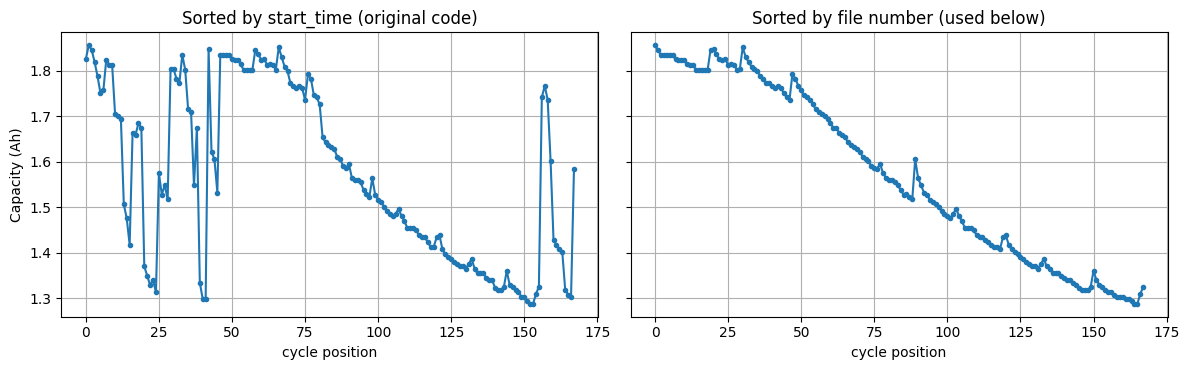

If the left plot zigzags and the right plot decays smoothly, the original order was scrambled.


In [3]:
# CELL 3: ordering check for B0005 (start_time sort versus file-number sort)
d = cell_table('B0005')
print("start_time dtype:", d['start_time'].dtype, "| example:", repr(d['start_time'].iloc[0]))

by_time = d.sort_values('start_time')
by_file = d.sort_values('file_no')
same = (by_time['file_no'].to_numpy() == by_file['file_no'].to_numpy())
print(f"cycles where the two orderings agree: {same.sum()} of {len(d)}")
print("Spearman(order by start_time, order by file number):",
      round(spearmanr(np.arange(len(by_time)), by_time['file_no'].to_numpy())[0], 4))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
ax[0].plot(by_time['Capacity'].to_numpy(), marker='.'); ax[0].set_title("Sorted by start_time (original code)")
ax[1].plot(by_file['Capacity'].to_numpy(), marker='.'); ax[1].set_title("Sorted by file number (used below)")
for a in ax: a.set_xlabel("cycle position"); a.grid(True)
ax[0].set_ylabel("Capacity (Ah)")
plt.tight_layout(); plt.show()
print("If the left plot zigzags and the right plot decays smoothly, the original order was scrambled.")

## Features for all four cells (filtered), plus unfiltered B0005 for the ablation

In [4]:
# CELL 4: build feature tables
CELLS_USED = [b for b in ['B0005', 'B0006', 'B0007', 'B0018'] if b in set(df_meta['battery_id'])]
print("cells found:", CELLS_USED)
tables = {}
for b in CELLS_USED:
    tables[b] = extract_features(cell_table(b), use_filter=True)
    tables[b]['battery_id'] = b
    print(b, "cycles:", len(tables[b]),
          "| capacity %.3f -> %.3f Ah" % (tables[b]['capacity'].iloc[0], tables[b]['capacity'].iloc[-1]),
          "| duration range %.0f-%.0f s" % (tables[b]['duration_s'].min(), tables[b]['duration_s'].max()))
raw_b5 = extract_features(cell_table('B0005'), use_filter=False)

# sanity: capacity should be close to current x time / 3600 (coulomb counting) -> shows how strongly duration encodes the target
b5 = tables['B0005']
print("corr(duration_s, capacity) on B0005:", round(np.corrcoef(b5['duration_s'], b5['capacity'])[0, 1], 4))
print("duration_s versus original code's feature (sample count): mean seconds per sample =",
      round((b5['duration_s'] / b5['n_samples']).mean(), 2))

cells found: ['B0005', 'B0006', 'B0007', 'B0018']
B0005 cycles: 168 | capacity 1.856 -> 1.325 Ah | duration range 2792-3690 s
B0006 cycles: 168 | capacity 2.035 -> 1.186 Ah | duration range 2792-3690 s
B0007 cycles: 168 | capacity 1.891 -> 1.432 Ah | duration range 2792-3690 s
B0018 cycles: 132 | capacity 1.855 -> 1.341 Ah | duration range 2743-3435 s
corr(duration_s, capacity) on B0005: 0.9755
duration_s versus original code's feature (sample count): mean seconds per sample = 11.09


## Experiment 1: baselines, ablations and hyperparameter search on B0005 (chronological 80/20 split)
Models use a `MinMaxScaler` fitted on the training cycles only (your original code had no scaling, although the paper described it).
Hyperparameters are chosen with forward-chaining cross-validation (`TimeSeriesSplit`) on the training cycles only.

B0005: 134 training cycles (cycles 1-134), 34 test cycles (cycles 135-168)

Selected hyperparameters (paper Table 4):
  SVR {'C': 10, 'epsilon': 0.001, 'gamma': 'auto'}
  RF {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 100}
  XGB {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 100}

===== TABLE 6 (paper): baselines and ablations, B0005 test cycles =====
                                                     MAE    RMSE        R2
Training-mean baseline                            0.3104  0.3111 -195.2336
Linear regression on duration only                0.0519  0.0522   -4.5268
SVR alone                                         0.0056  0.0063    0.9195
RF alone                                          0.0441  0.0493   -3.9285
XGB alone                                         0.0419  0.0468   -3.4438
Simple average of SVR, RF, XGB                    0.0305  0.0341   -1.3607
Stacked ensemble, Ridge meta-learner (proposed)   0.0024  0.0028    0.9841
Stacked ensemble, Linea

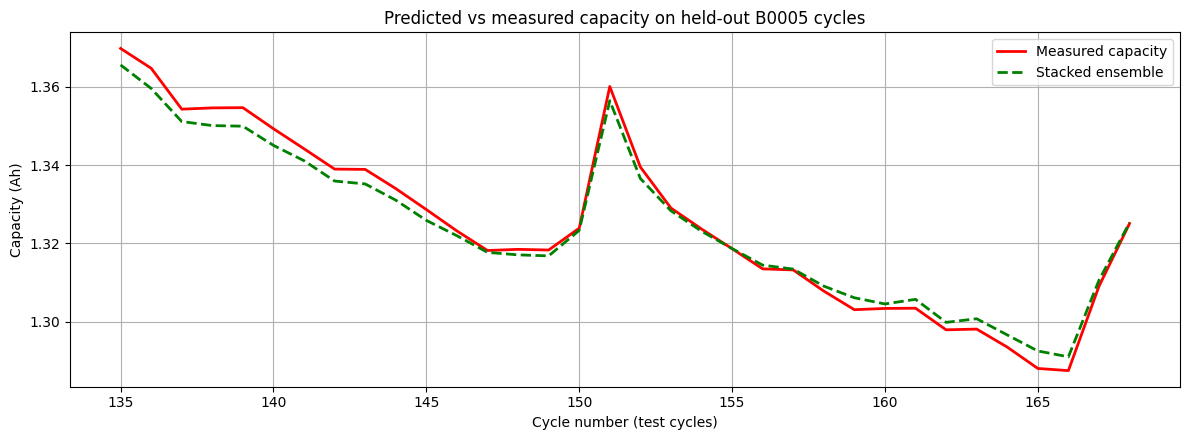

In [5]:
# CELL 5: models, tuning, evaluation
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.linear_model import RidgeCV, LinearRegression
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, KFold
from sklearn.dummy import DummyRegressor
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

def scaled(model):
    return Pipeline([('scale', MinMaxScaler()), ('m', model)])

def metrics(y, p):
    return dict(MAE=mean_absolute_error(y, p), RMSE=float(np.sqrt(mean_squared_error(y, p))), R2=r2_score(y, p))

def tune(X, y):
    specs = {
        'SVR': (scaled(SVR(kernel='rbf')), {'m__C': [1, 10, 100], 'm__epsilon': [0.001, 0.01, 0.05], 'm__gamma': ['scale', 'auto']}),
        'RF':  (scaled(RandomForestRegressor(random_state=SEED)), {'m__n_estimators': [100, 300], 'm__max_depth': [None, 5, 10], 'm__min_samples_leaf': [1, 3]}),
        'XGB': (scaled(XGBRegressor(random_state=SEED, verbosity=0)), {'m__n_estimators': [100, 300], 'm__learning_rate': [0.05, 0.1], 'm__max_depth': [3, 5]}),
    }
    best, params = {}, {}
    for name, (est, grid) in specs.items():
        gs = GridSearchCV(est, grid, cv=TimeSeriesSplit(n_splits=5), scoring='neg_root_mean_squared_error', n_jobs=-1).fit(X, y)
        best[name], params[name] = gs.best_estimator_, {k.replace('m__', ''): v for k, v in gs.best_params_.items()}
    return best, params

def make_stack(best, meta='ridge'):
    final = RidgeCV(alphas=np.logspace(-3, 2, 12)) if meta == 'ridge' else LinearRegression()
    return StackingRegressor([(k.lower(), clone(v)) for k, v in best.items()], final_estimator=final, cv=KFold(n_splits=5), n_jobs=-1)

b5 = tables['B0005']
n_test = int(np.ceil(0.2 * len(b5))); split = len(b5) - n_test      # identical to train_test_split(test_size=0.2, shuffle=False)
tr, te = b5.iloc[:split], b5.iloc[split:]
print(f"B0005: {len(tr)} training cycles (cycles 1-{split}), {len(te)} test cycles (cycles {split+1}-{len(b5)})")
Xtr, ytr, Xte, yte = tr[FEATS], tr['capacity'], te[FEATS], te['capacity']

best, best_params = tune(Xtr, ytr)
print("\nSelected hyperparameters (paper Table 4):")
for k, v in best_params.items(): print(" ", k, v)

rows, preds = {}, {}
dummy = DummyRegressor(strategy='mean').fit(Xtr, ytr);                       preds['Training-mean baseline'] = dummy.predict(Xte)
dur = scaled(LinearRegression()).fit(Xtr[['duration_s']], ytr);              preds['Linear regression on duration only'] = dur.predict(Xte[['duration_s']])
for k in ['SVR', 'RF', 'XGB']:
    preds[k + ' alone'] = best[k].predict(Xte)
preds['Simple average of SVR, RF, XGB'] = np.mean([best[k].predict(Xte) for k in ['SVR', 'RF', 'XGB']], axis=0)
stack_ridge = make_stack(best, 'ridge').fit(Xtr, ytr);                       preds['Stacked ensemble, Ridge meta-learner (proposed)'] = stack_ridge.predict(Xte)
stack_lin = make_stack(best, 'linear').fit(Xtr, ytr);                        preds['Stacked ensemble, Linear-regression meta-learner'] = stack_lin.predict(Xte)

nod = make_stack({k: v for k, v in best.items()}, 'ridge').fit(Xtr.drop(columns='duration_s'), ytr)
preds['Stack without Discharge Duration'] = nod.predict(Xte.drop(columns='duration_s'))
rtr, rte = raw_b5.iloc[:split], raw_b5.iloc[split:]
nof = make_stack(best, 'ridge').fit(rtr[FEATS], rtr['capacity'])
preds['Stack without Savitzky-Golay filter'] = nof.predict(rte[FEATS])

table6 = pd.DataFrame({k: metrics(yte if 'filter' not in k else rte['capacity'], p) for k, p in preds.items()}).T.round(4)
print("\n===== TABLE 6 (paper): baselines and ablations, B0005 test cycles =====")
print(table6.to_string())
print("\nRidge alpha chosen by the meta-learner:", getattr(stack_ridge.final_estimator_, 'alpha_', None))
print("Meta-learner weights (SVR, RF, XGB):", np.round(stack_ridge.final_estimator_.coef_, 3), "intercept", round(float(stack_ridge.final_estimator_.intercept_), 4))

plt.figure(figsize=(12, 4.5))
plt.plot(te['cycle'].to_numpy(), yte.to_numpy(), 'r-', lw=2, label='Measured capacity')
plt.plot(te['cycle'].to_numpy(), preds['Stacked ensemble, Ridge meta-learner (proposed)'], 'g--', lw=2, label='Stacked ensemble')
plt.xlabel('Cycle number (test cycles)'); plt.ylabel('Capacity (Ah)'); plt.grid(True); plt.legend()
plt.title('Predicted vs measured capacity on held-out B0005 cycles'); plt.tight_layout()
plt.savefig('fig3_pred_vs_actual.png', dpi=300); plt.show()

In [6]:
cc = lambda df: (-df['mean_i'] * df['duration_s'] / 3600.0)
print("raw:", {k: round(v, 4) for k, v in metrics(yte, cc(te)).items()})
cal = LinearRegression().fit(cc(tr).to_frame('cc'), ytr)
print("recalibrated:", {k: round(v, 4) for k, v in metrics(yte, cal.predict(cc(te).to_frame('cc'))).items()})

raw: {'MAE': 0.0046, 'RMSE': 0.0046, 'R2': 0.9566}
recalibrated: {'MAE': 0.0004, 'RMSE': 0.0004, 'R2': 0.9997}


## Experiment 2: leave-one-battery-out (B0005, B0006, B0007, B0018)
Hyperparameters from Experiment 1 are reused. Different cells have different discharge cut-off voltages, so `min_v` differs between cells; this is a real source of shift, mention it in the limitations.

In [7]:
# CELL 6: leave-one-battery-out
lobo_rows = []
for held in CELLS_USED:
    train_cells = [c for c in CELLS_USED if c != held]
    trn = pd.concat([tables[c] for c in train_cells]); tst = tables[held]
    stk = make_stack(best, 'ridge').fit(trn[FEATS], trn['capacity'])
    res = {'Stacked ensemble': stk.predict(tst[FEATS])}
    for k in ['SVR', 'RF', 'XGB']:
        res[k + ' alone'] = clone(best[k]).fit(trn[FEATS], trn['capacity']).predict(tst[FEATS])
    for name, p in res.items():
        lobo_rows.append(dict(test_cell=held, train_cells=", ".join(train_cells), model=name, **metrics(tst['capacity'], p)))
table7 = pd.DataFrame(lobo_rows)
print("===== TABLE 7 (paper): leave-one-battery-out =====")
print(table7.round(4).to_string(index=False))
print("\nMean over held-out cells:")
print(table7.groupby('model')[['MAE', 'RMSE', 'R2']].mean().round(4).to_string())

===== TABLE 7 (paper): leave-one-battery-out =====
test_cell         train_cells            model    MAE   RMSE     R2
    B0005 B0006, B0007, B0018 Stacked ensemble 0.0045 0.0053 0.9992
    B0005 B0006, B0007, B0018        SVR alone 0.0036 0.0046 0.9994
    B0005 B0006, B0007, B0018         RF alone 0.0434 0.0535 0.9207
    B0005 B0006, B0007, B0018        XGB alone 0.0380 0.0464 0.9402
    B0006 B0005, B0007, B0018 Stacked ensemble 0.0084 0.0103 0.9983
    B0006 B0005, B0007, B0018        SVR alone 0.0120 0.0144 0.9967
    B0006 B0005, B0007, B0018         RF alone 0.0398 0.0575 0.9477
    B0006 B0005, B0007, B0018        XGB alone 0.0416 0.0558 0.9507
    B0007 B0005, B0006, B0018 Stacked ensemble 0.0120 0.0130 0.9934
    B0007 B0005, B0006, B0018        SVR alone 0.0097 0.0104 0.9958
    B0007 B0005, B0006, B0018         RF alone 0.0259 0.0290 0.9673
    B0007 B0005, B0006, B0018        XGB alone 0.0263 0.0318 0.9606
    B0018 B0005, B0006, B0007 Stacked ensemble 0.0033 0.0040 0.99

## Experiment 3: operating conditions available in the dataset (comment 8)

In [8]:
# CELL 7: which operating conditions exist in the metadata?
dd = df_meta[df_meta['type'] == 'discharge'].copy()
dd['Capacity'] = pd.to_numeric(dd['Capacity'], errors='coerce')
agg = {'n_discharge_cycles': ('filename', 'count'), 'first_capacity_Ah': ('Capacity', 'first'), 'min_capacity_Ah': ('Capacity', 'min')}
if 'ambient_temperature' in dd.columns:
    agg['ambient_temperature_C'] = ('ambient_temperature', lambda s: sorted(set(s.dropna())))
cond = dd.groupby('battery_id').agg(**agg)
cond['used_in_this_paper'] = cond.index.isin(CELLS_USED)
print(cond.to_string())
print("\nIf several ambient temperatures appear above, you can test a cell at another temperature and report it in Section VII-F.")

            n_discharge_cycles  first_capacity_Ah  min_capacity_Ah ambient_temperature_C  used_in_this_paper
battery_id                                                                                                  
B0005                      168           1.856487         1.287453                  [24]                True
B0006                      168           2.035338         1.153818                  [24]                True
B0007                      168           1.891052         1.400455                  [24]                True
B0018                      132           1.855005         1.341051                  [24]                True
B0025                       28           1.847011         1.767789                  [24]               False
B0026                       28           1.813250         1.386337                  [24]               False
B0027                       28           1.823308         1.770093                  [24]               False
B0028              

## Experiment 4: SHAP on the full stacked ensemble (comment 6)
Your original code explained only the **XGBoost base learner** with `TreeExplainer`, not the ensemble. Here the explainer is applied to the ensemble's `predict`, and the additivity check is printed.

PermutationExplainer explainer: 35it [00:37,  1.57s/it]


SHAP base value (mean ensemble prediction over the training background): 1.6436 Ah
Additivity: max |base + sum(SHAP) - prediction| over test cycles = 1.51e-09 Ah

Mean |SHAP| per feature (global importance):
Discharge Duration (s)    0.1689
Mean Current (A)          0.1280
Mean Voltage (V)          0.0129
Max Temperature (C)       0.0072
Min Voltage (V)           0.0024


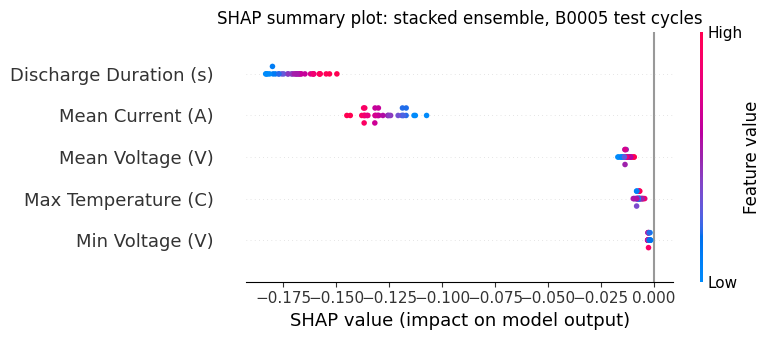


Training range per feature (is the dashboard example inside it?):
            train_min  train_max  example  inside_range
mean_v          3.479      3.564      3.5          True
min_v           2.788      2.959      2.7         False
mean_i         -1.938     -1.710     -2.0         False
max_t          37.721     41.358     32.0         False
duration_s   2882.906   3690.234   3100.0          True

Dashboard example: predicted capacity 1.7247 Ah, SoH 86.23%
Base value 1.6436 Ah
Local SHAP values (paper Table 9):
Mean Voltage (V)         -0.0063
Min Voltage (V)           0.0013
Mean Current (A)          0.0964
Max Temperature (C)       0.0350
Discharge Duration (s)   -0.0453
base + sum(SHAP) = 1.7247 Ah (should equal the prediction 1.7247)


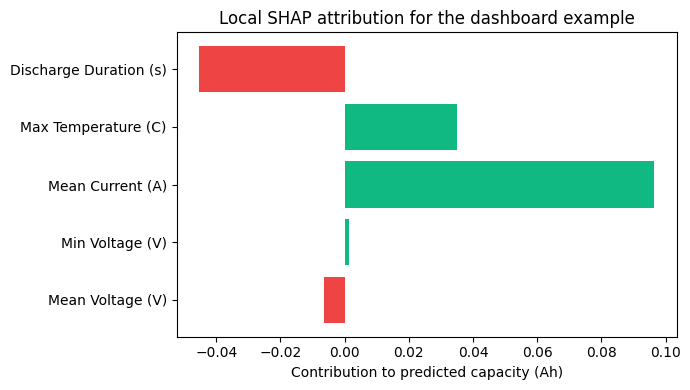

In [9]:
# CELL 8: SHAP on the stacked ensemble, additivity check, and the dashboard example (paper Tables 8 and 9)
import shap
explainer = shap.Explainer(stack_ridge.predict, Xtr, algorithm='permutation', seed=SEED)
sv = explainer(Xte)
pred_te = stack_ridge.predict(Xte)
add_err = np.abs(sv.base_values + sv.values.sum(axis=1) - pred_te)
print("SHAP base value (mean ensemble prediction over the training background): %.4f Ah" % float(np.mean(sv.base_values)))
print("Additivity: max |base + sum(SHAP) - prediction| over test cycles = %.2e Ah" % add_err.max())

imp = pd.Series(np.abs(sv.values).mean(axis=0), index=FEAT_LABELS).sort_values(ascending=False)
print("\nMean |SHAP| per feature (global importance):"); print(imp.round(4).to_string())

plt.figure(); shap.summary_plot(sv.values, Xte.to_numpy(), feature_names=FEAT_LABELS, show=False)
plt.title('SHAP summary plot: stacked ensemble, B0005 test cycles'); plt.tight_layout(); plt.savefig('fig4_shap_summary.png', dpi=300); plt.show()

# dashboard example of the paper (Table 8)
x0 = pd.DataFrame([[3.50, 2.70, -2.0, 32.0, 3100.0]], columns=FEATS)
print("\nTraining range per feature (is the dashboard example inside it?):")
rng = pd.DataFrame({'train_min': Xtr.min(), 'train_max': Xtr.max(), 'example': x0.iloc[0]})
rng['inside_range'] = (rng['example'] >= rng['train_min']) & (rng['example'] <= rng['train_max'])
print(rng.round(3).to_string())
p0 = float(stack_ridge.predict(x0)[0]); s0 = explainer(x0)
print("\nDashboard example: predicted capacity %.4f Ah, SoH %.2f%%" % (p0, p0 / 2.0 * 100))
print("Base value %.4f Ah" % float(s0.base_values[0]))
loc = pd.Series(s0.values[0], index=FEAT_LABELS)
print("Local SHAP values (paper Table 9):"); print(loc.round(4).to_string())
print("base + sum(SHAP) = %.4f Ah (should equal the prediction %.4f)" % (float(s0.base_values[0] + loc.sum()), p0))

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(FEAT_LABELS, loc.values, color=['#10b981' if v > 0 else '#ef4444' for v in loc.values])
ax.set_xlabel('Contribution to predicted capacity (Ah)'); ax.set_title('Local SHAP attribution for the dashboard example')
plt.tight_layout(); plt.savefig('fig5_local_shap.png', dpi=300); plt.show()

## Dashboard latency (paper Table 5) and the updated dashboard

In [10]:
# CELL 9: latency of one dashboard query (prediction + SHAP)
def dashboard_infer(x):
    return float(stack_ridge.predict(x)[0]), explainer(x)
dashboard_infer(x0)  # warm-up
ts = []
for _ in range(20):
    t0 = time.perf_counter(); dashboard_infer(x0); ts.append((time.perf_counter() - t0) * 1000)
print("Latency per query (prediction + SHAP): mean %.0f ms, median %.0f ms, max %.0f ms" % (np.mean(ts), np.median(ts), np.max(ts)))

Latency per query (prediction + SHAP): mean 1200 ms, median 953 ms, max 1876 ms


In [11]:
# CELL 10 (optional): the dashboard rebuilt on the fixed model, with SHAP of the full ensemble
!pip install gradio -q
import gradio as gr

def predict_battery_health(mean_v, min_v, mean_c, max_t, duration):
    x = pd.DataFrame([[mean_v, min_v, mean_c, max_t, duration]], columns=FEATS)
    cap, s = dashboard_infer(x)
    soh = cap / 2.0 * 100
    alert = ("CRITICAL: severe degradation" if soh < 70 else "WARNING: health declining" if soh < 80 else "HEALTHY: normal operating conditions")
    vals = s.values[0]
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.barh(FEAT_LABELS, vals, color=['#10b981' if v > 0 else '#ef4444' for v in vals])
    ax.set_xlabel("Contribution to predicted capacity (Ah)"); ax.set_title("Local SHAP attribution"); plt.tight_layout()
    return f"{cap:.4f} Ah", f"{soh:.2f}%", alert, fig

with gr.Blocks() as dashboard:
    gr.Markdown("## Battery SoH dashboard (simulated demonstrator: manually entered telemetry, not a live BMS feed)")
    with gr.Row():
        with gr.Column():
            a = gr.Slider(3.0, 4.2, value=3.5, label="Mean Voltage (V)")
            b = gr.Slider(2.0, 3.5, value=2.7, label="Minimum Voltage (V)")
            c = gr.Slider(-4.0, 0.0, value=-2.0, label="Mean Current (A)")
            d_ = gr.Slider(20.0, 60.0, value=32.0, label="Peak surface temperature (C)")
            e = gr.Slider(1000, 5000, value=3100, step=10, label="Discharge duration (s)")
            btn = gr.Button("Run inference")
        with gr.Column():
            o1 = gr.Textbox(label="Predicted capacity"); o2 = gr.Textbox(label="State of Health"); o3 = gr.Textbox(label="Status"); o4 = gr.Plot()
    btn.click(predict_battery_health, [a, b, c, d_, e], [o1, o2, o3, o4])
dashboard.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://4be97190ba46935955.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [12]:
# CELL 11: NUMBERS FOR THE PAPER (copy this whole output back to Claude)
print("== split ==", f"train cycles 1-{split} (n={len(tr)}), test cycles {split+1}-{len(b5)} (n={len(te)})")
print("== hyperparameters =="); print(best_params)
print("== Table 6 =="); print(table6.to_string())
print("== Table 7 =="); print(table7.round(4).to_string(index=False))
print("== SHAP importance =="); print(imp.round(4).to_string())
print("== SHAP example =="); print("pred", round(p0, 4), "base", round(float(s0.base_values[0]), 4), "local", loc.round(4).to_dict())
print("== latency ms (mean) ==", round(float(np.mean(ts))))

== split == train cycles 1-134 (n=134), test cycles 135-168 (n=34)
== hyperparameters ==
{'SVR': {'C': 10, 'epsilon': 0.001, 'gamma': 'auto'}, 'RF': {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 100}, 'XGB': {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 100}}
== Table 6 ==
                                                     MAE    RMSE        R2
Training-mean baseline                            0.3104  0.3111 -195.2336
Linear regression on duration only                0.0519  0.0522   -4.5268
SVR alone                                         0.0056  0.0063    0.9195
RF alone                                          0.0441  0.0493   -3.9285
XGB alone                                         0.0419  0.0468   -3.4438
Simple average of SVR, RF, XGB                    0.0305  0.0341   -1.3607
Stacked ensemble, Ridge meta-learner (proposed)   0.0024  0.0028    0.9841
Stacked ensemble, Linear-regression meta-learner  0.0023  0.0028    0.9846
Stack without Discharge Durat

In [13]:
x1 = Xte.iloc[[15]]   # cycle 150
print("measured", float(yte.iloc[15]), "predicted", float(stack_ridge.predict(x1)[0]))
s1 = explainer(x1); print(pd.Series(s1.values[0], index=FEAT_LABELS).round(4), "base", float(s1.base_values[0]))

measured 1.323872422244268 predicted 1.3233101425913452
Mean Voltage (V)         -0.0128
Min Voltage (V)          -0.0025
Mean Current (A)         -0.1295
Max Temperature (C)      -0.0074
Discharge Duration (s)   -0.1680
dtype: float64 base 1.6435558133427242
